# Problem 3: Iterative Closest Point

All of your code goes in `P3_icp.py`. The source is a partial scan of the Stanford Bunny and the target is the full bunny model.

In [58]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt

from P3_icp import apply_transform, nearest_neighbors, best_fit_transform, icp

os.makedirs("plots", exist_ok=True)

data = np.load("data/bunny.npz")
model = data["model"].astype(float)
scan = data["scan"].astype(float)[::4]  # every 4th point, for speed
T_init = data["T_init"]
T_ref = data["T_ref"]  # reference alignment, used only to measure errors below
print(model.shape, scan.shape)

def rotation_angle_deg(Ra, Rb):
    return np.degrees(np.arccos(np.clip((np.trace(Ra.T @ Rb) - 1) / 2, -1, 1)))

def alignment_error(T, pts=scan):
    """Rotation error (deg) and mean point error (m) of T relative to the reference alignment."""
    return rotation_angle_deg(T[:3, :3], T_ref[:3, :3]), np.linalg.norm(apply_transform(T, pts) - apply_transform(T_ref, pts), axis=1).mean()

def plot_clouds(clouds, title, filename=None):
    fig = plt.figure(figsize=(6, 6))
    ax = fig.add_subplot(111, projection="3d")
    for pts, c, label in clouds:
        p = pts[::3]
        ax.scatter(p[:, 0], p[:, 2], p[:, 1], s=0.3, c=c, label=label)
    ax.view_init(elev=15, azim=-60)
    ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_zlabel("y")
    ax.set_title(title)
    ax.legend(markerscale=10)
    if filename is not None:
        plt.savefig(filename, bbox_inches="tight")
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(35947, 3) (10025, 3)


In [59]:
### EXTRA ONE
import plotly.graph_objects as go

def plot_clouds_plotly(clouds, title, filename=None):
    fig = go.Figure()

    for pts, c, label in clouds:
        p = pts[::3]

        fig.add_trace(go.Scatter3d(
            x=p[:, 0],
            y=p[:, 2],
            z=p[:, 1],
            mode="markers",
            marker=dict(size=1.5, color=c),
            name=label
        ))

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title="x",
            yaxis_title="z",
            zaxis_title="y",
            aspectmode="data",
            camera=dict(
                eye=dict(x=1.5, y=-1.5, z=0.5)
            )
        ),
        width=800,
        height=700,
        legend=dict(
            x=0,
            y=1
        )
    )

    if filename is not None:
        fig.write_html(filename)

    fig.show()

## Sanity Checks

In [60]:
rng = np.random.default_rng(0)
A = rng.normal(size=(50, 3))
a = 0.7
R_true = np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])
B = A @ R_true.T + np.array([0.3, -0.2, 0.1])
T = best_fit_transform(A, B)
print(T[:3, :3])
print(R_true)
print(np.allclose(T[:3, :3], R_true))
assert T.shape == (4, 4) and np.allclose(T[:3, :3], R_true) and np.allclose(T[:3, 3], [0.3, -0.2, 0.1])
dist, idx = nearest_neighbors(A[:5] + 1e-3, A)
print(dist, idx)
assert np.array_equal(idx, np.arange(5)) and np.allclose(dist, np.sqrt(3) * 1e-3)
print("Sanity checks passed")

[[ 7.64842187e-01 -6.44217687e-01  0.00000000e+00]
 [ 6.44217687e-01  7.64842187e-01  5.55111512e-17]
 [-1.03080801e-16  3.15756037e-16  1.00000000e+00]]
[[ 0.76484219 -0.64421769  0.        ]
 [ 0.64421769  0.76484219  0.        ]
 [ 0.          0.          1.        ]]
True
[0.00173205 0.00173205 0.00173205 0.00173205 0.00173205] [0 1 2 3 4]
Sanity checks passed


## Basic ICP

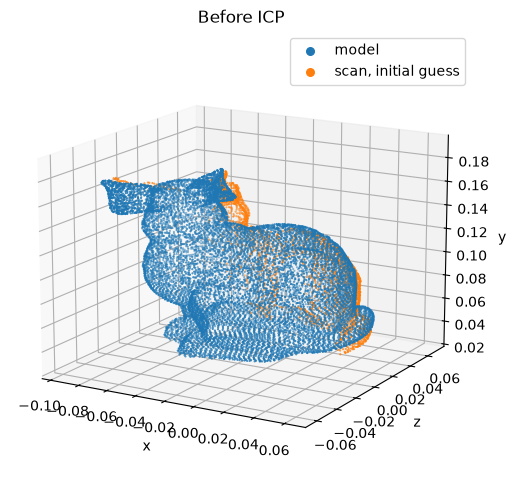

iterations: 100, final mean NN distance: 0.00052 m
rotation error 0.043 deg, mean point error 0.00005 m


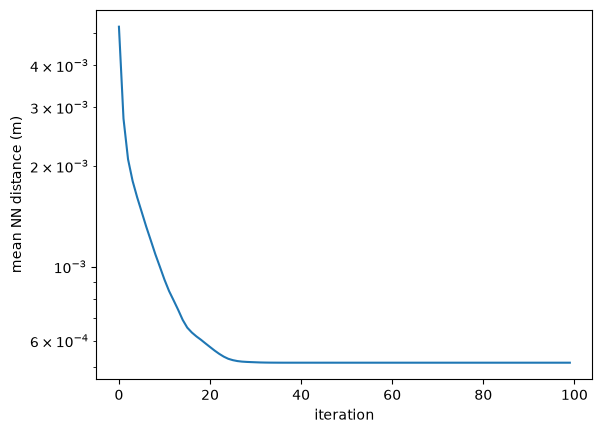

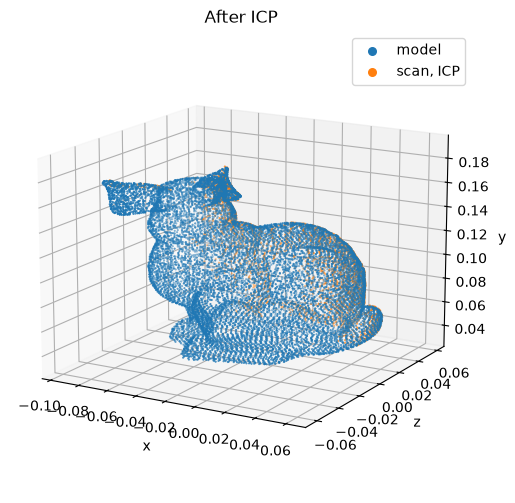

In [61]:
plot_clouds([(model, "tab:blue", "model"), (apply_transform(T_init, scan), "tab:orange", "scan, initial guess")], "Before ICP")

T, errors = icp(scan, model, T_init, max_iters=100, tol=1e-7)
rot_err, pt_err = alignment_error(T)
print("iterations: %d, final mean NN distance: %.5f m" % (len(errors), errors[-1]))
print("rotation error %.3f deg, mean point error %.5f m" % (rot_err, pt_err))

plt.figure()
plt.semilogy(errors)
plt.xlabel("iteration")
plt.ylabel("mean NN distance (m)")
plt.show()

plot_clouds([(model, "tab:blue", "model"), (apply_transform(T, scan), "tab:orange", "scan, ICP")], "After ICP", "plots/p3_icp.png")

In [62]:

plot_clouds_plotly([(model, "blue", "model"), (apply_transform(T, scan), "orange", "scan, ICP")], "After ICP", "plots/p3_icp_plotly.html")

## Convergence Basin
Start ICP from the reference alignment rotated by an extra angle about the vertical axis. Use this for part (ii). This cell takes about a minute.

In [63]:
def rotate_about_vertical(T, deg):
    a = np.radians(deg)
    Ry = np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
    c = apply_transform(T, scan).mean(axis=0)
    P = np.eye(4)
    P[:3, :3] = Ry
    P[:3, 3] = c - Ry @ c
    return P @ T

print(" offset | iters | final NN dist | rot. error | point error")
for deg in [15, 30, 60, 90, 120]:
    T_o, err_o = icp(scan, model, rotate_about_vertical(T_ref, deg), max_iters=100, tol=1e-7)
    r, p = alignment_error(T_o)
    print(f" {deg:5d}  | {len(err_o):5d} |   {err_o[-1]:.5f}     | {r:7.2f} deg | {p:.5f} m")

 offset | iters | final NN dist | rot. error | point error
    15  |   100 |   0.00052     |    0.05 deg | 0.00006 m
    30  |   100 |   0.00052     |    0.05 deg | 0.00006 m
    60  |   100 |   0.00052     |    0.05 deg | 0.00006 m
    90  |   100 |   0.00518     |  144.68 deg | 0.07733 m
   120  |   100 |   0.00518     |  144.84 deg | 0.07741 m


## Outlier Rejection
Now the scan also contains points on the floor under the bunny, which have no match in the model. Use this for part (iii).

(12531, 3)
reject_dist = None: iterations 100, final mean NN distance 0.01221 m, rotation error 9.78 deg, point error 0.01246 m
reject_dist = 0.005: iterations 100, final mean NN distance 0.00986 m, rotation error 0.27 deg, point error 0.00038 m


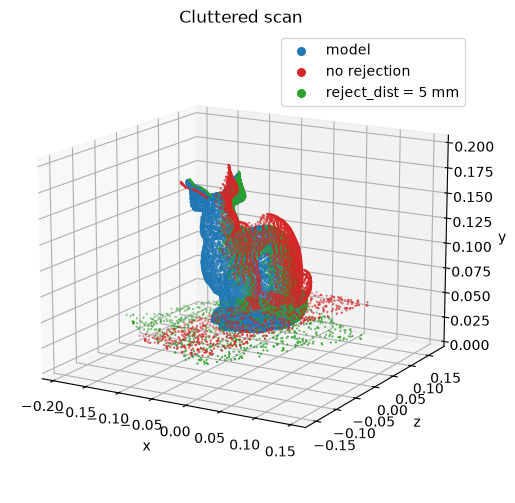

In [64]:
cluttered = np.vstack([scan, data["floor"].astype(float)])
print(cluttered.shape)

results = {}
for reject in [None, 0.005]:
    T_c, err_c = icp(cluttered, model, T_init, max_iters=100, tol=1e-7, reject_dist=reject)
    r, p = alignment_error(T_c)
    results[reject] = T_c
    print(f"reject_dist = {reject}: iterations {len(err_c)}, final mean NN distance {err_c[-1]:.5f} m, "
          f"rotation error {r:.2f} deg, point error {p:.5f} m")

plot_clouds([(model, "tab:blue", "model"), (apply_transform(results[None], cluttered), "tab:red", "no rejection"),
             (apply_transform(results[0.005], cluttered), "tab:green", "reject_dist = 5 mm")], "Cluttered scan", "plots/p3_clutter.png")

In [65]:

plot_clouds_plotly([(model, "blue", "model"), (apply_transform(results[None], cluttered), "red", "no rejection"),
             (apply_transform(results[0.005], cluttered), "green", "reject_dist = 5 mm")], "Cluttered scan", "plots/p3_clutter_plotly.html")